# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
%matplotlib inline
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy: 0.9722; F1 macro: 0.9710
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



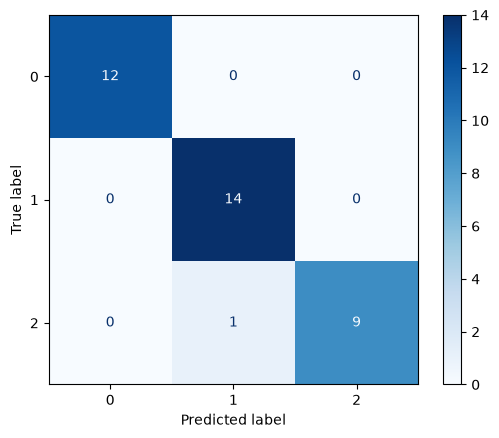

Confusiones (real, predicción, cantidad): [(2, 1, 1)]
Accuracy CV: 0.9790640394088669
Diferencia test-CV: -0.006841817186644672


In [4]:
from sklearn.metrics import confusion_matrix
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"Accuracy: {accuracy:.4f}; F1 macro: {f1_macro:.4f}")
print(classification_report(y_test, y_pred, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot(cmap="Blues")
plt.show()
confusions = [(int(model.classes_[i]), int(model.classes_[j]), int(cm[i,j]))
    for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i,j] > 0]
print("Confusiones (real, predicción, cantidad):", confusions)
print("Accuracy CV:", training_metadata["cv_accuracy"])
print("Diferencia test-CV:", accuracy - training_metadata["cv_accuracy"])

**Análisis:** La salida anterior compara el accuracy de test con la media de CV e identifica explícitamente cada confusión. Test contiene solo 36 vinos: un error cambia el accuracy aproximadamente 2,78 puntos porcentuales. Una diferencia pequeña no basta para concluir sobreajuste; la brecha train-CV y la variabilidad de CV aportan contexto. No se cambia el modelo después de mirar estos resultados. La conclusión numérica final aparece en el resumen ejecutado.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida esquema, preserva índice y aplica el pipeline completo."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError("Se requiere un DataFrame")
    if records.columns.duplicated().any():
        raise ValueError("Hay columnas duplicadas")
    missing = set(feature_columns) - set(records.columns)
    if missing:
        raise ValueError(f"Faltan columnas: {sorted(missing)}")
    X = records.loc[:, feature_columns].copy()
    if not all(pd.api.types.is_numeric_dtype(X[c]) for c in feature_columns):
        raise TypeError("Las características deben ser numéricas")
    if np.isinf(X.to_numpy(dtype=float)).any():
        raise ValueError("No se aceptan infinitos; NaN se imputa en el pipeline")
    result = pd.DataFrame(index=records.index)
    if len(X) == 0:
        return pd.DataFrame(columns=["prediction"] + [f"probability_{c}" for c in model.classes_], index=X.index)
    result["prediction"] = model.predict(X)
    probabilities = model.predict_proba(X)
    for j, label in enumerate(model.classes_):
        result[f"probability_{label}"] = probabilities[:, j]
    return result

## 4. Predicción por lotes

In [6]:
# Simulación con test; no se presenta como observaciones nuevas reales.
new_records = X_test.iloc[:5].copy()
batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
display(batch_predictions)
assert np.allclose(batch_predictions.filter(like="probability_").sum(axis=1), 1)
assert predict(new_records[feature_columns[::-1]]).equals(batch_predictions)
try:
    predict(new_records.drop(columns=feature_columns[0]))
except ValueError:
    print("Validación de columnas faltantes: correcta")
else:
    raise AssertionError("Se aceptó un esquema incompleto")

,prediction,probability_0,probability_1,probability_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


Validación de columnas faltantes: correcta


## 5. Reporte final

In [7]:
metrics = {"model": training_metadata["champion"], "accuracy": float(accuracy),
    "f1_macro": float(f1_macro), "n_test": len(y_test), "confusions": confusions}
(REPORTS_DIR / "test_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
from IPython.display import Markdown
display(Markdown(f"""| Elemento | Resultado |
|---|---|
| Modelo campeón | {training_metadata['champion']} |
| Accuracy CV | {training_metadata['cv_accuracy']:.4f} |
| Accuracy test | {accuracy:.4f} |
| F1 macro test | {f1_macro:.4f} |
| Confusiones (real, predicción, n) | {confusions or 'Ninguna'} |
| Principal limitación | Solo {len(y_test)} vinos en test; generalización a otras fuentes no validada |"""))

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression |
| Accuracy CV | 0.9791 |
| Accuracy test | 0.9722 |
| F1 macro test | 0.9710 |
| Confusiones (real, predicción, n) | [(2, 1, 1)] |
| Principal limitación | Solo 36 vinos en test; generalización a otras fuentes no validada |

In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

La tabla de la celda anterior se genera a partir de las métricas reales, para que permanezca consistente al volver a ejecutar.

- [x] Solo se evaluó el campeón.
- [x] No se reajustó tras observar test.
- [x] Se validó el esquema y el orden de columnas.
- [x] Se generaron predicciones por lotes y métricas persistidas.

### Conclusión de esta ejecución

El campeón acertó **35 de 36** vinos: accuracy **97,22 %**, F1 macro **0,9710**. El único error fue clase real 2 predicha como 1. El accuracy queda 0,68 puntos porcentuales por debajo de CV (97,91 %), una diferencia menor al efecto de una sola observación de test y a la dispersión entre folds. No hay evidencia fuerte de sobreajuste adicional en este test, pero 36 muestras no permiten asegurar generalización a nuevas bodegas o condiciones de medición.
